# 03 · Modelagem do Klike Score

> **Parte 2 do desafio:** construir um modelo preditivo para o `klike_score`. Quais features e por quê, qual modelo, como avaliar e quais variáveis mais influenciam o score.

A modelagem segue um protocolo definido antes dos experimentos formais (seção 4). O histórico do repositório registra o protocolo antes dos resultados.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from klike import modeling, viz
from klike.analysis import (
    CONTEXT_WITHIN_PLATFORM,
    CREATIVE_TERMS,
    add_rate_metrics,
    estimate_effects,
    fit_model,
)
from klike.config import CATEGORY_ORDERS, TARGET
from klike.data import load_clean, load_raw
from klike.formatting import fmt_compact, fmt_number, fmt_pct, fmt_signed, fmt_signed_pct
from klike.modeling import (
    FeatureSpec,
    bootstrap_mae_gain,
    bootstrap_metrics,
    build_pipeline,
    compare_on_splits,
    evaluate_on_splits,
    linear_effects,
    out_of_fold_predictions,
    outer_splits,
    pairwise_concordance,
    permutation_importance_by_group,
    prepare_features,
    prepare_post_flight_features,
    split_development_test,
    tuned,
)
from klike.predictor import train_final_model

viz.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 140)
PLATFORMS = ["Meta", "TikTok", "LinkedIn"]
cleaned = load_clean()

## 1. Dois cenários de previsão

A decisão que guia o case também guia o modelo: separar o que existe antes da veiculação do que só existe depois.

| | Modelo A · pré-publicação | Modelo B · pós-publicação |
| :-- | :-- | :-- |
| **Usa** | Contexto da campanha e atributos do criativo | Tudo do modelo A, mais taxas de performance |
| **Responde** | Quanto do score dá para prever antes de gastar | Quanto o score acompanha a performance realizada |
| **Papel** | Principal: pontua criativos novos e apoia o recommendations engine | Comparativo: não serve para um criativo que ainda não foi veiculado |

Duas ressalvas valem para tudo o que vem a seguir:

- **Reproduzir o Klike Score não é prever vendas.** O alvo é o score da própria Klike, numa base simulada. Um bom modelo aqui mostra que o score é previsível a partir do criativo, não que o criativo garante resultado financeiro.
- **Prever, pesar na previsão e causar são coisas diferentes.** O modelo pode prever bem o score, e uma variável pode pesar muito na previsão, sem que isso prove que mudar essa variável melhora a performance.

## 2. Features declaradas

O modelo A recebe exatamente 13 colunas, todas conhecidas antes da veiculação. Elas ficam declaradas em `src/klike/modeling.py`, e um teste impede que métricas de performance, o próprio score, o identificador ou a data entrem no modelo.

| Grupo | Colunas | Tratamento |
| :-- | :-- | :-- |
| Contexto | plataforma, categoria, objetivo, faixa etária, retargeting | Categorias e sim/não. Retargeting é decisão de mídia: o engine não pode mudá-lo no criativo |
| Criativo | hook, rosto, CTA, legenda, formato, densidade de texto, duração, música/voz | Densidade de texto como categoria, porque o efeito não é monotônico (Parte 1). Legenda sem marcação vira a categoria "desconhecida" |
| Fora do modelo A | identificador, data, métricas de performance, score | O identificador não generaliza; a data serve só para a checagem temporal; a performance só existe depois do gasto |

**Faltantes.** Duração, música/voz e legenda podem faltar, como no histórico. Na legenda, a ausência já é uma categoria própria, "desconhecida". Duração e música/voz são imputadas pela mediana dentro do pipeline, com o que foi aprendido só no treino de cada partição. Indicadores de ausência para essas duas não entram por padrão: só entram se o experimento F1 mostrar que ajudam. A duração em log também é um experimento (F2).

**Uma única preparação para treino e inferência.** A função `prepare_features` converte e valida as 13 colunas, e é a mesma para o histórico e para uma campanha nova. Ela não depende da limpeza da Parte 1, que exige métricas que uma campanha nova ainda não tem. E a limpeza não mexe em nenhuma das 13 colunas: só corrige métricas de performance.

In [2]:
same = prepare_features(load_raw()).equals(prepare_features(cleaned))
print(
    "Features do modelo A idênticas no CSV bruto e na base limpa: "
    + ("sim" if same else "não")
)
display(prepare_features(cleaned).head(3))

Features do modelo A idênticas no CSV bruto e na base limpa: sim


,platform,category,objective,target_audience_age,format,text_density,subtitle_status,is_retargeting,has_hook,has_face,has_cta,video_duration_s,music_voice_ratio
0,Meta,Branding,awareness,18-24,vertical,medium,sim,0,0,1,1,NaN,0.39
1,LinkedIn,App Install,traffic,25-34,horizontal,low,sim,0,1,1,1,NaN,0.07
2,TikTok,SaaS,traffic,25-34,vertical,medium,sim,0,1,1,1,8.0,0.43


Uma campanha nova só precisa dos campos de pré-publicação. Entradas inválidas geram um erro que lista todos os problemas, em vez de uma previsão silenciosamente errada:

In [3]:
new_campaign = {
    "platform": "TikTok",
    "category": "E-commerce",
    "objective": "conversions",
    "target_audience_age": "18-24",
    "is_retargeting": False,
    "format": "vertical",
    "has_hook": True,
    "has_face": False,
    "has_cta": True,
    "text_density": "low",
    "has_subtitle": None,
    "video_duration_s": 15,
}
display(prepare_features(new_campaign))
try:
    prepare_features({**new_campaign, "platform": "Tiktok", "music_voice_ratio": 1.5})
except ValueError as error:
    print(error)

,platform,category,objective,target_audience_age,format,text_density,subtitle_status,is_retargeting,has_hook,has_face,has_cta,video_duration_s,music_voice_ratio
0,TikTok,E-commerce,conversions,18-24,vertical,low,desconhecido,0,1,0,1,15.0,NaN


Entrada inválida: platform: valor desconhecido ['Tiktok'] (aceitos: Meta, TikTok, LinkedIn); music_voice_ratio: esperado um número entre 0 e 1, ou ausente.


**Modelo B.** Acrescenta sete taxas: CTR, engajamento, retenção, conversão por clique, conversões por mil impressões, CPC e ROAS. Volumes, como impressões e gasto, ficam de fora, porque medem verba. O ROAS não se aplica a Branding: ali ele vale 0, e a categoria Branding, que já está no modelo, absorve a diferença de nível. Assim, a relação com o ROAS é aprendida só com as campanhas que medem receita.

## 3. Experimentos exploratórios, antes do protocolo

> **Leia como exploração, não como desempenho.** Estes experimentos foram feitos para planejar a modelagem, antes de existir a divisão entre desenvolvimento e teste. Usaram as 500 campanhas, inclusive as que depois foram para o teste. O código abaixo é o do diagnóstico original, mantido como foi rodado.

A pergunta era: quanto do score cada grupo de informação explica, e um modelo não linear ganha de um linear?

In [4]:
explore = add_rate_metrics(cleaned)
score = explore[TARGET]
CONTEXT = ["platform", "category", "objective", "target_audience_age"]
CREATIVE_CAT = ["format", "text_density", "subtitle"]
CREATIVE_BIN = ["has_hook", "has_face", "has_cta", "is_retargeting"]
POST = ["ctr", "engagement_rate", "completion_rate", "conversion_rate",
        "conversions_per_mille", "cpc", "roas"]

X_explore = explore.copy()
X_explore["subtitle"] = (
    X_explore["has_subtitle"].map({True: "sim", False: "não"}).fillna("desconhecido")
)
for col in CONTEXT + ["format", "text_density"]:
    X_explore[col] = X_explore[col].astype(str)
for col in CREATIVE_BIN:
    X_explore[col] = X_explore[col].astype(int)
X_explore["log_duration"] = np.log(X_explore["video_duration_s"])


def exploratory_linear(cats, nums):
    columns = ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cats),
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                              StandardScaler()), nums),
    ])
    return make_pipeline(columns, LinearRegression())


def exploratory_boosting(cats, nums):
    columns = ColumnTransformer([("cat", OrdinalEncoder(), cats), ("num", "passthrough", nums)])
    boosting = HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=20,
        categorical_features=list(range(len(cats))), random_state=0,
    )
    return make_pipeline(columns, boosting)


PRE_NUM = CREATIVE_BIN + ["log_duration", "music_voice_ratio"]
CREATIVE_NUM = ["has_hook", "has_face", "has_cta", "log_duration", "music_voice_ratio"]
TREE_NUM = CREATIVE_BIN + ["video_duration_s", "music_voice_ratio"]
explorations = {
    "Média (baseline)": (make_pipeline(DummyRegressor()), ["platform"]),
    "Só contexto, linear": (exploratory_linear(CONTEXT, ["is_retargeting"]),
                            CONTEXT + ["is_retargeting"]),
    "Só criativo, linear": (exploratory_linear(CREATIVE_CAT, CREATIVE_NUM),
                            CREATIVE_CAT + CREATIVE_NUM),
    "Pré-publicação, linear": (exploratory_linear(CONTEXT + CREATIVE_CAT, PRE_NUM),
                               CONTEXT + CREATIVE_CAT + PRE_NUM),
    "Pré-publicação, boosting": (exploratory_boosting(CONTEXT + CREATIVE_CAT, TREE_NUM),
                                 CONTEXT + CREATIVE_CAT + TREE_NUM),
    "Pré + pós-publicação, linear": (exploratory_linear(CONTEXT + CREATIVE_CAT, PRE_NUM + POST),
                                     CONTEXT + CREATIVE_CAT + PRE_NUM + POST),
    "Só pós-publicação, linear": (exploratory_linear([], POST), POST),
}
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)
exploration = {}
for name, (model, cols) in explorations.items():
    result = cross_validate(
        model, X_explore[cols], score, cv=cv,
        scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"),
    )
    exploration[name] = {
        "MAE": fmt_number(-result["test_neg_mean_absolute_error"].mean(), 1),
        "RMSE": fmt_number(-result["test_neg_root_mean_squared_error"].mean(), 1),
        "R²": fmt_number(result["test_r2"].mean(), 2),
        "R², desvio entre partições": fmt_number(result["test_r2"].std(), 2),
    }
display(pd.DataFrame(exploration).T.rename_axis("exploração nas 500 campanhas"))

before_q4 = explore["date"].dt.quarter < 4
temporal = exploratory_linear(CONTEXT + CREATIVE_CAT, PRE_NUM).fit(
    X_explore.loc[before_q4, CONTEXT + CREATIVE_CAT + PRE_NUM], score[before_q4]
)
residual = score[~before_q4] - temporal.predict(
    X_explore.loc[~before_q4, CONTEXT + CREATIVE_CAT + PRE_NUM]
)
r2_q4 = 1 - (residual**2).sum() / ((score[~before_q4] - score[~before_q4].mean()) ** 2).sum()
print(
    f"Treino nos trimestres 1 a 3, avaliação no 4º ({(~before_q4).sum()} campanhas): "
    f"MAE {fmt_number(residual.abs().mean(), 1)} | R² {fmt_number(r2_q4, 2)}"
)

,MAE,RMSE,R²,"R², desvio entre partições"
exploração nas 500 campanhas,,,,
Média (baseline),"12,6","15,6","-0,02","0,02"
"Só contexto, linear","12,7","15,6","-0,02","0,05"
"Só criativo, linear","7,2","9,0","0,66","0,06"
"Pré-publicação, linear","6,9","8,7","0,68","0,06"
"Pré-publicação, boosting","7,4","9,3","0,63","0,07"
"Pré + pós-publicação, linear","5,5","7,0","0,79","0,03"
"Só pós-publicação, linear","9,6","12,0","0,39","0,08"


Treino nos trimestres 1 a 3, avaliação no 4º (136 campanhas): MAE 6,9 | R² 0,72


O que a exploração ensinou, e o que decidimos com ela:

| Aprendizado | Decisão |
| :-- | :-- |
| Só o contexto não prevê o score. Criativo e contexto juntos explicam cerca de dois terços da variação (R² de 0,68) | O modelo A, de pré-publicação, é o principal |
| O modelo linear superou o boosting nesta exploração (R² de 0,68 contra 0,63), coerente com os efeitos aditivos da Parte 1 | A Ridge entra como candidata principal, não como vencedora: a comparação formal, com ajuste justo dos dois, decide |
| As métricas de performance acrescentam explicação (R² de 0,79), mas só existem depois do gasto | Elas ficam no modelo B, comparativo |
| Treinar nos três primeiros trimestres e avaliar no quarto não piorou o resultado (R² de 0,72) | A checagem temporal entra no protocolo como robustez |

Uma consequência importante: a EDA e esta exploração viram as 500 campanhas, inclusive as que depois foram para o teste. Por isso, o teste não é totalmente intocado em relação às escolhas do plano. O protocolo limita esse efeito, com poucas hipóteses definidas antes e o teste consultado uma única vez, mas não o elimina.

## 4. Protocolo

Definido antes dos experimentos formais.

### Divisão e validação

- **Desenvolvimento e teste.** 400 campanhas para desenvolvimento e 100 para o teste final, sorteadas com estratificação por plataforma. O teste só é consultado uma vez, depois que modelo, features e hiperparâmetros estiverem decididos.
- **Validação cruzada aninhada no desenvolvimento.** As mesmas 25 partições externas (5 partes × 5 repetições, estratificadas por plataforma) valem para todos os candidatos. Os hiperparâmetros são escolhidos dentro do treino de cada partição externa, com 3 partes internas e pelo MAE. Assim, o ajuste nunca vê a parte que avalia o candidato.
- **Variabilidade.** Cada métrica vem com média e desvio entre as 25 partições. As partições repetidas compartilham campanhas: a variação mostra estabilidade, mas elas não são amostras independentes, e por isso nenhum teste estatístico formal é feito sobre elas.
- **Checagem temporal, complementar.** Dentro do desenvolvimento, treinar nos três primeiros trimestres e avaliar no quarto. Ela investiga se o desempenho se mantém no tempo, mas um ano de dados simulados não prova estabilidade.

### Candidatos e hiperparâmetros

| Candidato | Papel | Hiperparâmetros testados | Por quê |
| :-- | :-- | :-- | :-- |
| Dummy | Piso: prevê a média do treino | Nenhum | Todo modelo precisa superar este piso |
| Ridge | Linear e interpretável | Penalização (alpha) de 0,01 a 100, em 5 valores | Vai de quase nenhuma penalização a uma penalização forte |
| HistGradientBoosting | Não linear | Taxa de aprendizado 0,05 ou 0,1; 4 ou 8 folhas; mínimo de 10 ou 30 campanhas por folha; 200 iterações | Árvores rasas, com folhas que juntam campanhas suficientes, porque cada treino tem 320 campanhas |

O HistGradientBoosting usa o suporte nativo a categorias, com os códigos fixos da lista de categorias do projeto. Treino e inferência codificam do mesmo jeito, e um teste garante isso. O número de iterações é fixo, sem early stopping: ele reservaria parte de um treino que já é pequeno para a validação interna, e a semente fixa já garante a reprodução dos resultados. Os valores abaixo vêm direto do código:

In [5]:
print(f"Divisão: {1 - modeling.TEST_SIZE:.0%} desenvolvimento, {modeling.TEST_SIZE:.0%} teste")
print(f"Partições externas: {modeling.N_SPLITS} partes × {modeling.N_REPEATS} repetições")
print(f"Partes internas para o ajuste de hiperparâmetros: {modeling.INNER_FOLDS}")
for model, grid in modeling.PARAM_GRIDS.items():
    print(f"{model}: {grid}")
print(f"hgb, fixos: {modeling.HGB_FIXED}")
print(
    "Interação plataforma × formato: combinações com pelo menos "
    f"{modeling.MIN_INTERACTION_SUPPORT} campanhas no treino de cada partição"
)

Divisão: 80% desenvolvimento, 20% teste
Partições externas: 5 partes × 5 repetições
Partes internas para o ajuste de hiperparâmetros: 3
ridge: {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
hgb: {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [4, 8], 'model__min_samples_leaf': [10, 30]}
hgb, fixos: {'max_iter': 200, 'early_stopping': False}
Interação plataforma × formato: combinações com pelo menos 10 campanhas no treino de cada partição


### Experimentos formais

| ID | Hipótese | Comparação | Quando roda |
| :-- | :-- | :-- | :-- |
| M1 | Os efeitos são aditivos, então um modelo linear basta | Dummy, Ridge e HistGradientBoosting | Sempre, primeiro |
| F1 | A ausência seria informativa: se faltar um valor dissesse algo sobre o score, o indicador ajudaria. A Parte 1 indica que não | Com e sem indicadores de ausência para duração e música/voz | Para o vencedor de M1 |
| F2 | Se a duração tiver efeito, ele diminui conforme o vídeo fica mais longo | Duração original contra duração em log | Só se o vencedor for linear: árvores não mudam com transformações que preservam a ordem |
| F3 | O efeito do formato depende da plataforma | Com e sem a interação: colunas por combinação no linear, uma categoria combinada nas árvores. Só combinações com pelo menos 10 campanhas no treino de cada partição viram coluna no linear; TikTok horizontal, sem nenhuma campanha, nunca ganha efeito próprio, e nas árvores uma combinação ausente do treino é tratada como valor ausente | Para o vencedor de M1 |

A pertinência de cada experimento é revista conforme o vencedor de M1, e todo experimento rodado ou descartado vem com a justificativa. Resultados negativos também ficam registrados.

### Como decidir

A métrica principal é o MAE, em pontos de score; RMSE, R² e Spearman são complementares. As referências abaixo orientam a decisão, mas não são regras automáticas:

- **Relevância.** Uma alternativa mais complexa precisa melhorar o MAE de forma que importe. Como referência, cerca de 0,5 ponto, perto de 7% do erro esperado. A decisão olha também a melhora relativa e a variabilidade.
- **Estabilidade.** A melhora deve aparecer na grande maioria das 25 partições, com 80% como referência. Isso indica consistência, não significância estatística, porque as partições não são independentes.
- **Custo.** Complexidade e perda de interpretabilidade contam contra. Na dúvida, fica a alternativa mais simples.

### Avaliação final e diagnósticos

- **Certificação única no teste.** MAE, RMSE, R² e Spearman do modelo escolhido, treinado nas 400 campanhas, com intervalo de bootstrap e comparados ao baseline.
- **Erros por segmento.** Por plataforma e categoria, sempre com o tamanho de cada grupo, nas previsões fora da amostra do desenvolvimento.
- **Calibração e extremos.** Erro médio por faixa de score previsto, que deve ficar perto de zero. Nos extremos do score real, o erro é analisado à parte, explicando a regressão à média: todo modelo de regressão puxa as previsões para o centro, então superestima os scores muito baixos e subestima os muito altos.
- **Ordenação de criativos.** Em que porcentagem dos pares o modelo aponta o criativo de maior score. A análise olha pares da mesma plataforma e separa os pares pela diferença real de score: pares quase empatados não informam uma decisão de marketing. A leitura de negócio usa diferenças de pelo menos 10 pontos, e a tabela mostra também as outras faixas.
- **Interpretação.** Coeficientes em pontos e importância por permutação nas variáveis originais, separando alavancas do criativo de contexto, comparadas com a Parte 1 e com a ressalva de correlação entre variáveis.
- **Modelo B.** O mesmo protocolo, certificado depois do modelo A.

### Depois da certificação

O modelo é reajustado nas 500 campanhas para uso no recommendations engine. As métricas reportadas são as da certificação, do modelo treinado nas 400 campanhas; a versão reajustada não tem métrica própria. O arquivo do modelo não vai para o repositório: o código treina e salva de novo, com os metadados. O modelo salvo leva junto o suporte histórico das combinações de atributos, para o engine sinalizar incerteza e evitar extrapolações em grupos pequenos. A previsão terá uma interface única, que valida, prepara e prevê numa só chamada, sem permitir que alguma etapa seja esquecida.

### Limitações registradas antes dos resultados

- A EDA e a exploração da seção 3 viram as 500 campanhas, inclusive as do teste.
- Não há identificador de criativo. Nenhuma campanha repete todas as variáveis de pré-publicação de outra, o que é um bom sinal, mas não prova que versões do mesmo anúncio não estejam em lados diferentes da divisão.
- A base é simulada, e o alvo é o score da Klike, não um resultado de negócio.

## 5. Divisão e baseline

In [6]:
development, test = split_development_test(cleaned)
sizes = {
    "base inteira": cleaned["platform"].value_counts(),
    "desenvolvimento": development["platform"].value_counts(),
    "teste": test["platform"].value_counts(),
}
display(
    pd.DataFrame(
        {
            name: [f"{counts[p]} ({fmt_pct(counts[p] / counts.sum())})" for p in PLATFORMS]
            for name, counts in sizes.items()
        },
        index=PLATFORMS,
    ).rename_axis("campanhas por plataforma")
)

splits = outer_splits(development)
print(
    f"{len(splits)} partições externas, cada uma com {len(splits[0][0])} campanhas de treino "
    f"e {len(splits[0][1])} de validação"
)

,base inteira,desenvolvimento,teste
campanhas por plataforma,,,
Meta,"241 (48,2%)","193 (48,2%)",48 (48%)
TikTok,"176 (35,2%)","141 (35,2%)",35 (35%)
LinkedIn,"83 (16,6%)","66 (16,5%)",17 (17%)


25 partições externas, cada uma com 320 campanhas de treino e 80 de validação


In [7]:
X_development, y_development = prepare_features(development), development[TARGET]
baseline = evaluate_on_splits(build_pipeline("dummy"), X_development, y_development, splits)
display(
    pd.DataFrame(
        {
            "média": baseline[["mae", "rmse", "r2"]].mean(),
            "desvio entre partições": baseline[["mae", "rmse", "r2"]].std(),
            "menor": baseline[["mae", "rmse", "r2"]].min(),
            "maior": baseline[["mae", "rmse", "r2"]].max(),
        }
    )
    .rename(index={"mae": "MAE", "rmse": "RMSE", "r2": "R²"})
    .map(lambda v: fmt_number(round(v, 2) + 0.0, 2))  # + 0.0 evita "-0,00"
    .rename_axis("baseline: média do treino")
)

,média,desvio entre partições,menor,maior
baseline: média do treino,,,,
MAE,"12,82","0,89","10,91","14,57"
RMSE,"15,87","0,96","14,03","17,76"
R²,"-0,01","0,02","-0,08","0,00"


**O piso.** Prevendo sempre a média do treino, o erro médio é de 12,8 pontos, numa escala de 0 a 100, e varia de 10,9 a 14,6 entre as partições. O R² fica perto de zero, como esperado para quem não usa nenhuma informação. Todo candidato da Etapa 2 é comparado a este piso, nas mesmas 25 partições.

O conjunto de teste está separado e não foi usado: nenhuma métrica dele aparece até a certificação.

## 6. Experimentos formais

Todos rodam no desenvolvimento, nas mesmas 25 partições, com os hiperparâmetros ajustados dentro do treino de cada partição. O teste continua intocado.

### 6.1 M1 · Algoritmos

**Hipótese.** A Parte 1 mostrou efeitos aditivos e nenhuma diferença robusta de efeito entre plataformas ou públicos. Se for assim, um modelo linear basta, e um modelo não linear não deveria ganhar dele.

**Comparação.** Dummy, Ridge e HistGradientBoosting, com o conjunto base de features, cada um com o seu espaço de hiperparâmetros (seção 4).

In [8]:
m1 = {
    "Dummy": evaluate_on_splits(build_pipeline("dummy"), X_development, y_development, splits),
    "Ridge": evaluate_on_splits(tuned("ridge"), X_development, y_development, splits),
    "HistGradientBoosting": evaluate_on_splits(
        tuned("hgb"), X_development, y_development, splits
    ),
}
METRIC_LABELS = {"mae": "MAE", "rmse": "RMSE", "r2": "R²", "spearman": "Spearman"}


def mean_and_spread(folds: pd.DataFrame, metric: str) -> str:
    """Média e desvio entre partições, no formato '7,01 ± 0,50'."""
    values = folds[metric]
    if values.isna().all():
        return "não se aplica"
    return f"{fmt_number(values.mean(), 2)} ± {fmt_number(values.std(), 2)}"


def paired(candidate: pd.DataFrame, reference: pd.DataFrame) -> dict:
    """Comparação pareada, nas mesmas partições, pelo MAE e pelo RMSE."""
    mae = compare_on_splits(candidate, reference)
    rmse = compare_on_splits(candidate, reference, metric="rmse")
    return {
        "redução do MAE (pontos)": fmt_signed(mae["melhora"], 2),
        "redução relativa": fmt_signed_pct(mae["melhora_relativa"], 1),
        "desvio da diferença": fmt_number(mae["desvio"], 2),
        "partições melhores (MAE)": fmt_pct(mae["vitorias"]),
        "partições melhores (RMSE)": fmt_pct(rmse["vitorias"]),
    }


display(
    pd.DataFrame(
        {
            name: {label: mean_and_spread(folds, metric) for metric, label in METRIC_LABELS.items()}
            for name, folds in m1.items()
        }
    ).T.rename_axis("média ± desvio entre as 25 partições")
)
display(
    pd.DataFrame(
        {
            "Ridge sobre o Dummy": paired(m1["Ridge"], m1["Dummy"]),
            "HistGradientBoosting sobre o Dummy": paired(m1["HistGradientBoosting"], m1["Dummy"]),
            "HistGradientBoosting sobre a Ridge": paired(m1["HistGradientBoosting"], m1["Ridge"]),
        }
    ).T.rename_axis("comparação pareada")
)
alphas = Counter(params["model__alpha"] for params in m1["Ridge"]["hiperparametros"])
leaves = Counter(
    params["model__max_leaf_nodes"] for params in m1["HistGradientBoosting"]["hiperparametros"]
)


def partitions(n: int) -> str:
    return f"{n} {'partição' if n == 1 else 'partições'}"


print(
    "Ridge, penalização escolhida: "
    + ", ".join(f"alpha {fmt_compact(a)} em {partitions(n)}" for a, n in alphas.most_common())
)
print(
    "HistGradientBoosting, tamanho das árvores escolhido: "
    + ", ".join(f"{size} folhas em {partitions(n)}" for size, n in leaves.most_common())
)

,MAE,RMSE,R²,Spearman
média ± desvio entre as 25 partições,,,,
Dummy,"12,82 ± 0,89","15,87 ± 0,96","-0,01 ± 0,02",não se aplica
Ridge,"7,01 ± 0,50","8,76 ± 0,71","0,69 ± 0,04","0,82 ± 0,02"
HistGradientBoosting,"7,24 ± 0,60","9,15 ± 0,78","0,66 ± 0,05","0,79 ± 0,03"


,redução do MAE (pontos),redução relativa,desvio da diferença,partições melhores (MAE),partições melhores (RMSE)
comparação pareada,,,,,
Ridge sobre o Dummy,"+5,82","+45,3%","0,73",100%,100%
HistGradientBoosting sobre o Dummy,"+5,58","+43,5%","0,68",100%,100%
HistGradientBoosting sobre a Ridge,"−0,23","−3,3%","0,37",32%,12%


Ridge, penalização escolhida: alpha 1 em 23 partições, alpha 0,01 em 1 partição, alpha 0,1 em 1 partição
HistGradientBoosting, tamanho das árvores escolhido: 4 folhas em 21 partições, 8 folhas em 4 partições


**O que aprendemos.** A Ridge erra, em média, 7,0 pontos numa escala de 0 a 100, contra 12,8 do piso: 45% menos erro, com melhora em todas as 25 partições. O HistGradientBoosting também supera o piso, mas erra em média 0,23 ponto a mais que a Ridge e só a supera em 32% das partições, ou 12% pelo RMSE. Ou seja, entre os candidatos e hiperparâmetros investigados, o HistGradientBoosting não mostrou vantagem sobre a Ridge. O ajuste interno preferiu as árvores mais simples do espaço testado, com 4 folhas, em 21 das 25 partições. Isso é compatível com essa conclusão, mas não prova que não existam relações não lineares: outros modelos, outros hiperparâmetros ou mais dados poderiam encontrá-las. A penalização da Ridge foi a mesma em 23 das 25 partições, então o ajuste dela é estável.

**Decisão: Ridge.** Erra menos, varia menos entre partições e é interpretável: cada coeficiente vira pontos de score, o que a Parte 3 vai usar. Como a vencedora é linear, os três experimentos de features são pertinentes.

### 6.2 F1 a F3 · Features, na Ridge

Cada experimento compara a Ridge base com a Ridge mais uma alteração, nas mesmas partições e com o mesmo ajuste interno.

| ID | Hipótese | Alteração testada |
| :-- | :-- | :-- |
| F1 | Se faltar um valor dissesse algo sobre o score, um indicador de ausência ajudaria. A Parte 1 indicou ausência compatível com acaso | Indicadores para duração e música/voz |
| F2 | Se a duração tiver efeito, ele diminui conforme o vídeo fica mais longo | Duração em log |
| F3 | O efeito do formato depende da plataforma, como sugeriu a Parte 1 | Interação plataforma × formato, nas combinações com suporte no treino |

In [9]:
base = m1["Ridge"]
feature_experiments = {
    "F1 · indicadores de ausência": FeatureSpec(missing_indicators=True),
    "F2 · duração em log": FeatureSpec(log_duration=True),
    "F3 · plataforma × formato": FeatureSpec(platform_format=True),
}
f_results = {
    name: evaluate_on_splits(tuned("ridge", spec), X_development, y_development, splits)
    for name, spec in feature_experiments.items()
}
display(
    pd.DataFrame(
        {
            name: {"MAE": mean_and_spread(folds, "mae"), **paired(folds, base)}
            for name, folds in f_results.items()
        }
    ).T.rename_axis("contra a Ridge base")
)


def interactions_in(train: np.ndarray) -> tuple[str, ...]:
    """Combinações de plataforma e formato com suporte no treino de uma partição."""
    pipeline = build_pipeline("ridge", FeatureSpec(platform_format=True))
    names = pipeline.fit(X_development.iloc[train], y_development.iloc[train])[0]
    return tuple(name for name in names.get_feature_names_out() if "×" in name)


for combinations, n in Counter(interactions_in(train) for train, _ in splits).items():
    print(f"F3, interações criadas em {n} das {len(splits)} partições: {', '.join(combinations)}")

,MAE,redução do MAE (pontos),redução relativa,desvio da diferença,partições melhores (MAE),partições melhores (RMSE)
contra a Ridge base,,,,,,
F1 · indicadores de ausência,"7,04 ± 0,51","−0,03","−0,4%","0,05",40%,36%
F2 · duração em log,"7,01 ± 0,51",0,0%,"0,04",56%,52%
F3 · plataforma × formato,"6,78 ± 0,48","+0,23","+3,3%","0,18",92%,96%


F3, interações criadas em 25 das 25 partições: TikTok × quadrado, LinkedIn × quadrado, LinkedIn × horizontal


**O que aprendemos, experimento por experimento:**

- **F1, indicadores de ausência: fica de fora.** O MAE piora 0,03 ponto, e a variante só é melhor em 40% das partições: os indicadores não trouxeram ganho preditivo consistente, o que justifica deixá-los de fora. O resultado é compatível com a Parte 1, que não encontrou relação entre a ausência e as variáveis observadas, mas não prova que a ausência seja completamente aleatória.
- **F2, duração em log: fica de fora.** O MAE não muda, e cada versão vence em cerca de metade das partições. Também é coerente com a Parte 1, onde a duração não mostrou efeito. No empate, fica a forma mais simples, a duração original.
- **F3, plataforma × formato: entra.** O MAE cai 0,23 ponto, ou 3,3%, com melhora em 92% das partições, e em 96% pelo RMSE. A melhora fica abaixo da referência de 0,5 ponto do protocolo, então a decisão pesou os outros critérios: ela é muito estável, custa só três termos, mantém o modelo linear e interpretável e deixa o efeito do formato específico de cada plataforma. Isso importa para o produto: sem a interação, o modelo aplicaria o mesmo efeito de formato a todas as plataformas, embora a Parte 1 tenha mostrado o vídeo horizontal com score menor na Meta e como o formato mais usado no LinkedIn. TikTok horizontal, que não aparece na base, nunca ganhou efeito próprio.

Como só uma alteração entrou, não há combinação de alterações a conferir.

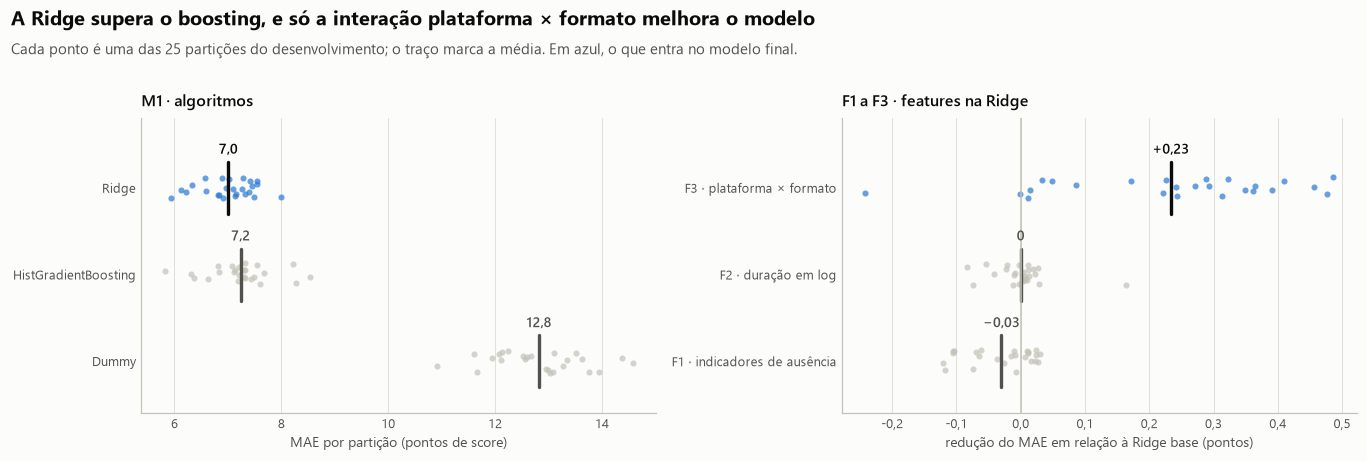

In [10]:
rng = np.random.default_rng(0)  # só para espalhar os pontos na vertical


def strip(ax, rows, highlight):
    """Uma linha por candidato: os valores das partições como pontos e a média como traço."""
    for y, (label, values, show) in enumerate(rows):
        chosen = label == highlight
        ink = viz.INK if chosen else viz.INK_SECONDARY
        ax.scatter(values, y + rng.uniform(-0.13, 0.13, len(values)), s=16, linewidth=0,
                   color=viz.ACCENT if chosen else viz.CONTEXT, alpha=0.7)
        mean = np.mean(values)
        ax.plot([mean, mean], [y - 0.3, y + 0.3], linewidth=2.2, color=ink)
        ax.text(mean, y + 0.36, show(mean), ha="center", va="bottom", fontsize=9, color=ink,
                fontweight="semibold")
    ax.set_yticks(range(len(rows)), [label for label, _, _ in rows])
    ax.set_ylim(-0.6, len(rows) - 0.2)
    ax.grid(axis="y", visible=False)


fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.3))
strip(
    left,
    [(name, m1[name]["mae"].to_numpy(), lambda v: fmt_number(v, 1))
     for name in ["Dummy", "HistGradientBoosting", "Ridge"]],
    highlight="Ridge",
)
left.xaxis.set_major_formatter(viz.decimal_formatter(0))
left.set_xlabel("MAE por partição (pontos de score)")
left.set_title("M1 · algoritmos")
strip(
    right,
    [(name, base["mae"].to_numpy() - folds["mae"].to_numpy(), lambda v: fmt_signed(v, 2))
     for name, folds in f_results.items()],
    highlight="F3 · plataforma × formato",
)
right.axvline(0, color=viz.BASELINE, linewidth=1)
right.xaxis.set_major_formatter(viz.decimal_formatter(1))
right.set_xlabel("redução do MAE em relação à Ridge base (pontos)")
right.set_title("F1 a F3 · features na Ridge")
viz.add_header(
    fig,
    "A Ridge supera o boosting, e só a interação plataforma × formato melhora o modelo",
    "Cada ponto é uma das 25 partições do desenvolvimento; o traço marca a média. "
    "Em azul, o que entra no modelo final.",
)
viz.save(fig, "03_selecao_modelo")
plt.show()

### 6.3 Especificação congelada

| Item | Escolha |
| :-- | :-- |
| Algoritmo | Ridge, com a penalização escolhida por validação cruzada interna |
| Features | As 13 de pré-publicação: categorias contra a referência, binárias em 0 ou 1, duração e música/voz imputadas pela mediana do treino e padronizadas |
| Alteração adotada | Interação plataforma × formato, nas combinações com pelo menos 10 campanhas no treino (F3) |
| Alterações descartadas | Indicadores de ausência (F1) e duração em log (F2) |

A especificação fica registrada no código e é a que vai para a certificação no teste. Até aqui, o teste não foi consultado.

**Uma ressalva sobre o número.** O MAE de 6,78 da especificação escolhida vem das mesmas partições que orientaram a escolha. Por isso, pode trazer algum otimismo de seleção e não substitui a avaliação final nas 100 campanhas reservadas.

In [11]:
print(f"Modelo escolhido: {modeling.SELECTED_MODEL} | features: {modeling.SELECTED_SPEC}")

Modelo escolhido: ridge | features: FeatureSpec(missing_indicators=False, log_duration=False, platform_format=True)


## 7. Certificação no teste

> **Esta é a única consulta ao teste para o modelo principal.** A especificação foi congelada na seção 6, e nenhum resultado abaixo volta a mudá-la. Reexecutar o notebook reproduz os mesmos números, mas eles não orientam nenhuma escolha. O modelo B, comparativo, só é certificado na seção 10, depois deste resultado.

O modelo escolhido é treinado nas 400 campanhas de desenvolvimento, com a penalização definida por validação cruzada interna, e avaliado nas 100 campanhas reservadas. O Dummy, treinado nas mesmas 400, é o piso; a validação cruzada da seção 6 é o que se esperava. Os intervalos de 95% vêm de reamostrar as 100 campanhas do teste com o modelo já treinado: medem a incerteza de avaliar em 100 campanhas, não a de treinar o modelo de novo com outra amostra.

In [12]:
X_test, y_test = prepare_features(test), test[TARGET]
certified = tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC).fit(
    X_development, y_development
)
test_predictions = certified.predict(X_test)
baseline_predictions = build_pipeline("dummy").fit(X_development, y_development).predict(X_test)
model_test = bootstrap_metrics(y_test, test_predictions)
baseline_test = bootstrap_metrics(y_test, baseline_predictions)
expected = f_results["F3 · plataforma × formato"]  # validação cruzada da especificação escolhida


def with_interval(table: pd.DataFrame, metric: str) -> str:
    """Estimativa com o intervalo de 95% do bootstrap, como '6,71 (5,80 a 7,66)'."""
    row = table.loc[metric]
    if pd.isna(row["estimativa"]):
        return "não se aplica"
    # Arredondar antes evita um "-0,00" quando o valor é negativo, mas muito perto de zero.
    estimate, low, high = (
        fmt_number(round(row[key], 2) + 0.0, 2)
        for key in ["estimativa", "ic_inferior", "ic_superior"]
    )
    return f"{estimate} ({low} a {high})"


def by_metric(show) -> dict:
    """Uma coluna de tabela: a mesma formatação aplicada a cada métrica."""
    return {label: show(metric) for metric, label in METRIC_LABELS.items()}


display(
    pd.DataFrame(
        {
            "modelo escolhido, no teste": by_metric(lambda m: with_interval(model_test, m)),
            "Dummy, no teste": by_metric(lambda m: with_interval(baseline_test, m)),
            "modelo escolhido, validação cruzada": by_metric(
                lambda m: mean_and_spread(expected, m)
            ),
        }
    ).rename_axis("teste: estimativa (intervalo de 95%) | validação: média ± desvio")
)
gain = bootstrap_mae_gain(y_test, test_predictions, baseline_predictions)
test_residuals = y_test.to_numpy() - test_predictions
test_errors = np.abs(test_residuals)
print(f"Penalização escolhida: alpha {fmt_compact(certified.best_params_['model__alpha'])}")
print(
    f"Redução do MAE sobre o Dummy: {fmt_number(gain['estimativa'], 2)} pontos, com intervalo "
    f"de 95% de {fmt_number(gain['ic_inferior'], 2)} a {fmt_number(gain['ic_superior'], 2)}"
)
print(
    f"Campanhas do teste com erro abaixo de 5 pontos: {fmt_pct((test_errors < 5).mean())}; "
    f"abaixo de 10 pontos: {fmt_pct((test_errors < 10).mean())}"
)
print(
    f"Previsões no teste: de {fmt_number(test_predictions.min(), 1)} "
    f"a {fmt_number(test_predictions.max(), 1)}"
)

,"modelo escolhido, no teste","Dummy, no teste","modelo escolhido, validação cruzada"
teste: estimativa (intervalo de 95%) | validação: média ± desvio,,,
MAE,"6,43 (5,55 a 7,33)","11,67 (10,09 a 13,39)","6,78 ± 0,48"
RMSE,"7,92 (6,86 a 8,96)","14,37 (12,58 a 16,11)","8,50 ± 0,67"
R²,"0,70 (0,57 a 0,78)","0,00 (-0,06 a 0,00)","0,71 ± 0,04"
Spearman,"0,83 (0,74 a 0,88)",não se aplica,"0,83 ± 0,02"


Penalização escolhida: alpha 1
Redução do MAE sobre o Dummy: 5,24 pontos, com intervalo de 95% de 3,59 a 6,95
Campanhas do teste com erro abaixo de 5 pontos: 45%; abaixo de 10 pontos: 79%
Previsões no teste: de 35,5 a 85,0


**O resultado do teste é compatível com a validação cruzada.** Nas 100 campanhas reservadas, o modelo erra 6,43 pontos em média, com intervalo de 5,55 a 7,33, que inclui os 6,78 esperados. R² e Spearman também ficam onde a validação indicava. Contra o Dummy, o erro cai 5,24 pontos, com intervalo de 3,59 a 6,95: 45% menos que prever a média do treino. Em 45% das campanhas, o erro fica abaixo de 5 pontos, e em 79%, abaixo de 10.

- **O MAE do teste ficou um pouco abaixo do esperado,** dentro da variação de uma amostra de 100 campanhas. Isso reduz, mas não elimina, o risco de otimismo de seleção: a exploração preliminar da seção 3 teve contato com as 500 campanhas, inclusive as do teste. O teste também não mostra que o modelo seja melhor do que a validação indicava: com 100 campanhas, ele não separa diferenças de menos de cerca de 1 ponto.
- **O resultado é reportado como está e não muda nenhuma escolha.** A especificação é a da seção 6, e a penalização foi escolhida dentro do desenvolvimento, sem olhar o teste.

**Ordenação de criativos.** Em que porcentagem dos pares de criativos da mesma plataforma o modelo aponta o de maior score, separando os pares pela diferença real entre eles. Um modelo que chuta acerta metade. Em seguida, o erro do teste por plataforma.

In [13]:
def hit_rate(hits: pd.Series) -> pd.Series:
    """Acerto em porcentagem; faixas sem pares aparecem como tal."""
    return hits.map(lambda v: fmt_pct(v) if pd.notna(v) else "sem pares")


def show_concordance(table: pd.DataFrame) -> pd.DataFrame:
    return table.assign(acerto=hit_rate(table["acerto"])).rename_axis(
        "diferença real de score no par"
    )


def errors_by_group(groups: pd.Series, actual: pd.Series, residual, order: list[str]):
    """MAE com margem aproximada de 95% e viés por grupo, com o tamanho e a dispersão do grupo.

    A margem usa a aproximação normal, 1,96 desvio-padrão do erro sobre a raiz do tamanho do
    grupo. Ela é grosseira em grupos pequenos e serve como ordem de grandeza.
    """
    frame = pd.DataFrame(
        {"grupo": groups.astype(str).to_numpy(), "real": actual.to_numpy(), "erro": residual}
    ).assign(absoluto=lambda t: t["erro"].abs())
    table = (
        frame.groupby("grupo")
        .agg(
            campanhas=("erro", "size"),
            mae=("absoluto", "mean"),
            desvio=("absoluto", "std"),
            vies=("erro", "mean"),
            dispersao=("real", "std"),
        )
        .loc[order]
    )
    margin = 1.96 * table["desvio"] / np.sqrt(table["campanhas"])
    return pd.DataFrame(
        {
            "campanhas": table["campanhas"],
            "MAE (margem aproximada de 95%)": [
                f"{fmt_number(m, 1)} ± {fmt_number(e, 1)}"
                for m, e in zip(table["mae"], margin, strict=True)
            ],
            "viés médio (real − previsto)": table["vies"].map(lambda v: fmt_signed(v, 1)),
            "desvio do score real": table["dispersao"].map(lambda v: fmt_number(v, 1)),
        }
    )


display(show_concordance(pairwise_concordance(y_test, test_predictions, test["platform"])))
display(
    errors_by_group(test["platform"], y_test, test_residuals, PLATFORMS).rename_axis(
        "teste, por plataforma"
    )
)

,pares,acerto
diferença real de score no par,,
menos de 5 pontos,353,"54,4%"
5 a 10 pontos,325,"67,4%"
10 a 20 pontos,556,"89,2%"
20 pontos ou mais,623,"98,4%"
10 pontos ou mais,1179,"94,1%"
todos os pares,1857,"81,9%"


,campanhas,MAE (margem aproximada de 95%),viés médio (real − previsto),desvio do score real
"teste, por plataforma",,,,
Meta,48,"5,8 ± 1,2","−0,9","13,9"
TikTok,35,"7,9 ± 1,6","+0,8","15,9"
LinkedIn,17,"5,1 ± 2,1","+0,1","13,0"


- **A ordenação se confirma.** Nos pares com diferença real de 10 pontos ou mais, o modelo aponta o melhor criativo em 94% das vezes; abaixo de 5 pontos, em 54%, quase um chute. Os pares saem das mesmas 100 campanhas e não são independentes, então as porcentagens são descritivas. A seção 8.4 repete a análise no desenvolvimento.
- **Por plataforma, o teste é só descritivo.** Com 17 a 48 campanhas por grupo, as margens são largas. Elas vêm de uma aproximação normal, que é grosseira em grupos pequenos, como as 17 campanhas do LinkedIn. O TikTok erra mais, 7,9 ± 1,6, e o LinkedIn, menos, 5,1 ± 2,1: a ordem inversa da do desenvolvimento (seção 8.3). As margens se sobrepõem às de lá, e as 17 campanhas do LinkedIn no teste têm scores menos dispersos, com desvio de 13,0 pontos contra 16,4 no desenvolvimento, o que facilita a previsão. Para segmentos, a referência é o desenvolvimento, com quatro vezes mais campanhas.

## 8. Onde o modelo erra

Os diagnósticos usam as previsões fora da amostra do desenvolvimento: na primeira repetição das partições, cada uma das 400 campanhas é prevista por um modelo que não a viu. São quatro vezes mais campanhas que o teste para olhar faixas e segmentos, sem consultar o teste de novo.

### 8.1 Calibração por faixa de score previsto

Se o modelo é bem calibrado, o erro médio (real menos previsto) fica perto de zero em cada faixa de score previsto.

In [14]:
development_predictions = out_of_fold_predictions(
    tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC),
    X_development,
    y_development,
    splits[: modeling.N_SPLITS],
)
residuals = y_development - development_predictions
print(
    f"Fora da amostra no desenvolvimento: MAE {fmt_number(residuals.abs().mean(), 2)}; "
    f"erro abaixo de 5 pontos em {fmt_pct((residuals.abs() < 5).mean())} das campanhas "
    f"e abaixo de 10 pontos em {fmt_pct((residuals.abs() < 10).mean())}"
)

edges = np.quantile(development_predictions, np.linspace(0, 1, 6))
band_labels = [
    f"{fmt_number(low, 0)} a {fmt_number(high, 0)}"
    for low, high in zip(edges[:-1], edges[1:], strict=True)
]
calibration = (
    pd.DataFrame(
        {
            "faixa": pd.cut(
                development_predictions, edges, labels=band_labels, include_lowest=True
            ),
            "previsto": development_predictions,
            "real": y_development,
            "erro": residuals,
        }
    )
    .groupby("faixa", observed=True)
    .agg(
        campanhas=("erro", "size"),
        previsto=("previsto", "mean"),
        real=("real", "mean"),
        erro=("erro", "mean"),
        desvio=("erro", "std"),
    )
)
calibration["margem"] = 1.96 * calibration["desvio"] / np.sqrt(calibration["campanhas"])
display(
    pd.DataFrame(
        {
            "campanhas": calibration["campanhas"],
            "previsto médio": calibration["previsto"].map(lambda v: fmt_number(v, 1)),
            "real médio": calibration["real"].map(lambda v: fmt_number(v, 1)),
            "erro médio (margem de 95%)": [
                f"{fmt_signed(e, 1)} ± {fmt_number(m, 1)}"
                for e, m in zip(calibration["erro"], calibration["margem"], strict=True)
            ],
        }
    ).rename_axis("faixa de score previsto")
)

Fora da amostra no desenvolvimento: MAE 6,77; erro abaixo de 5 pontos em 42,2% das campanhas e abaixo de 10 pontos em 77,2%


,campanhas,previsto médio,real médio,erro médio (margem de 95%)
faixa de score previsto,,,,
9 a 49,80,"40,3","40,3","0 ± 1,9"
49 a 57,80,"52,8","53,9","+1,1 ± 1,9"
57 a 64,80,"60,1","60,9","+0,8 ± 1,9"
64 a 72,80,"68,1","68,1","0 ± 2,1"
72 a 92,80,"78,9","77,4","−1,4 ± 1,5"


**Bem calibrado.** Em todas as faixas, o erro médio fica entre −1,4 e +1,1 ponto, e o intervalo de 95% inclui o zero. Quando o modelo prevê 70, o score real fica, em média, perto de 70.

### 8.2 Os extremos do score real e a regressão à média

In [15]:
low_cut, high_cut = y_development.quantile([0.1, 0.9])
real_group = np.select(
    [y_development <= low_cut, y_development >= high_cut],
    ["10% com menor score real", "10% com maior score real"],
    default="80% do meio",
)
display(
    pd.DataFrame(
        {"grupo": real_group, "real": y_development, "previsto": development_predictions}
    )
    .assign(erro=lambda t: t["real"] - t["previsto"])
    .groupby("grupo")
    .agg(
        campanhas=("erro", "size"),
        real=("real", "mean"),
        previsto=("previsto", "mean"),
        erro=("erro", "mean"),
    )
    .loc[["10% com menor score real", "80% do meio", "10% com maior score real"]]
    .assign(
        real=lambda t: t["real"].map(lambda v: fmt_number(v, 1)),
        previsto=lambda t: t["previsto"].map(lambda v: fmt_number(v, 1)),
        erro=lambda t: t["erro"].map(lambda v: fmt_signed(v, 1)),
    )
    .rename(columns={"real": "real médio", "previsto": "previsto médio", "erro": "erro médio"})
    .rename_axis("grupo pelo score real")
)

,campanhas,real médio,previsto médio,erro médio
grupo pelo score real,,,,
10% com menor score real,40,"30,6","39,4","−8,8"
80% do meio,320,"60,7","60,2","+0,5"
10% com maior score real,40,"85,0","78,9","+6,1"


**Os extremos são puxados para o centro.** Nos 10% de scores reais mais altos, média de 85, o modelo prevê cerca de 79: subestima em 6 pontos. Nos 10% mais baixos, média de 31, prevê cerca de 39: superestima em 9. É o esperado, e não um sinal de viés: é regressão à média. Selecionar campanhas pelo score real tende a escolher as que tiveram, além dos atributos, um desvio a favor ou contra que o modelo não tem como prever. Qualquer modelo de regressão puxa as previsões para o centro quando não explica toda a variação. Por isso a calibração da seção 8.1, por score previsto, é a checagem certa de viés, e os extremos pedem outra leitura: para o produto, o modelo é melhor para separar criativos bons de fracos do que para cravar o score exato de um criativo excepcional.

### 8.3 Erros por plataforma e categoria

MAE e viés médio por segmento, com o tamanho e a dispersão de cada grupo. As margens de 95% são aproximações normais, mais confiáveis nos grupos grandes.

In [16]:
for column, label, order in [
    ("platform", "plataforma", PLATFORMS),
    ("category", "categoria", CATEGORY_ORDERS["category"]),
]:
    display(
        errors_by_group(development[column], y_development, residuals.to_numpy(), order)
        .rename_axis(label)
    )

,campanhas,MAE (margem aproximada de 95%),viés médio (real − previsto),desvio do score real
plataforma,,,,
Meta,193,"6,3 ± 0,7","+0,1","15,3"
TikTok,141,"6,8 ± 0,8","+0,2","16,0"
LinkedIn,66,"8,0 ± 1,4","−0,4","16,4"


,campanhas,MAE (margem aproximada de 95%),viés médio (real − previsto),desvio do score real
categoria,,,,
E-commerce,137,"7,1 ± 0,9",0,"14,0"
SaaS,73,"7,1 ± 1,2",0,"17,3"
Lead Gen,73,"7,5 ± 1,3","+0,4","16,9"
App Install,68,"5,8 ± 1,0","+0,1","17,1"
Branding,49,"5,5 ± 1,2",0,"14,9"


- **O LinkedIn é onde o modelo erra mais:** MAE de 8,0 ± 1,4, contra 6,3 ± 0,7 na Meta e 6,8 ± 0,8 no TikTok. Com 66 campanhas, a margem do LinkedIn é larga e se sobrepõe pouco à da Meta. É também a plataforma com menos campanhas para estimar os próprios efeitos, como o do formato (seção 9.2). No teste, a ordem se inverteu, dentro da incerteza de grupos pequenos (seção 7). Para o produto, previsões do LinkedIn pedem mais cautela.
- **Entre categorias, as margens se sobrepõem.** Os erros vão de 5,5 em Branding a 7,5 em Lead Gen, sem diferença clara para grupos de 49 a 137 campanhas.
- **Não encontramos evidência clara de viés médio sistemático nos segmentos avaliados.** O erro médio fica a menos de meio ponto de zero em todas as plataformas e categorias, o que não prova que o viés seja nulo.

### 8.4 Ordenação de criativos no desenvolvimento

A mesma análise de pares do teste, agora com as 400 campanhas do desenvolvimento, que dão muito mais pares. Os pares são separados pela diferença real de score, então esta é uma leitura retrospectiva:

In [17]:
display(
    show_concordance(
        pairwise_concordance(y_development, development_predictions, development["platform"])
    )
)

,pares,acerto
diferença real de score no par,,
menos de 5 pontos,5308,"58,4%"
5 a 10 pontos,5210,"71,1%"
10 a 20 pontos,8649,"85,3%"
20 pontos ou mais,11321,"97,0%"
10 pontos ou mais,19970,"91,9%"
todos os pares,30488,"82,5%"


**O modelo ordena bem o que importa.** Em pares da mesma plataforma com diferença real de 10 pontos ou mais, ele aponta o criativo melhor em 92% das vezes, e em 97% quando a diferença passa de 20. Em pares separados por menos de 5 pontos, acerta 58%, pouco acima de um chute: o modelo não distingue criativos quase equivalentes.

**Pela diferença prevista, a leitura do produto.** A diferença real só é conhecida depois da veiculação; antes dela, o produto conhece a diferença prevista entre dois criativos. A tabela abaixo separa os mesmos pares por essa diferença e mostra com que frequência o criativo de maior score previsto teve de fato o maior score real.

A análise é exploratória: não fazia parte do protocolo da seção 4 e complementa a leitura retrospectiva acima. Os pares compartilham campanhas e não são independentes, e previsões de partições diferentes vêm de modelos diferentes. Por isso, a última coluna repete a conta só com pares da mesma partição, previstos pelo mesmo modelo. Nenhum limiar é escolhido aqui, e o teste não é usado para isso.

In [18]:
fold = np.empty(len(development), dtype=int)
for number, (_, valid) in enumerate(splits[: modeling.N_SPLITS]):
    fold[valid] = number
platform_pairs, same_fold_pairs = (
    pairwise_concordance(
        y_development, development_predictions, groups, by="prevista", thresholds=(5, 10)
    )
    for groups in [
        development["platform"].astype(str),
        development["platform"].astype(str) + " | " + fold.astype(str),
    ]
)
display(
    pd.DataFrame(
        {
            "pares": platform_pairs["pares"],
            "parcela dos pares": (
                platform_pairs["pares"] / platform_pairs.loc["todos os pares", "pares"]
            ).map(fmt_pct),
            "acerto": hit_rate(platform_pairs["acerto"]),
            "acerto, só pares da mesma partição": hit_rate(same_fold_pairs["acerto"]),
        }
    ).rename_axis("diferença prevista no par")
)

,pares,parcela dos pares,acerto,"acerto, só pares da mesma partição"
diferença prevista no par,,,,
menos de 5 pontos,6024,"19,8%","58,4%","59,9%"
5 a 10 pontos,5719,"18,8%","73,7%",75%
10 a 20 pontos,9303,"30,5%","87,7%","87,1%"
20 pontos ou mais,9442,"31,0%","98,2%","98,2%"
5 pontos ou mais,24464,"80,2%","88,5%","88,6%"
10 pontos ou mais,18745,"61,5%","93,0%","92,7%"
todos os pares,30488,100%,"82,5%","82,7%"


- **Quanto maior a diferença prevista, mais confiável a comparação.** Com 10 pontos ou mais de diferença prevista, o criativo apontado teve de fato o maior score em 93,0% dos pares, que são 61,5% do total. Com 5 pontos ou mais, em 88,5% dos pares, que são 80,2% do total.
- **Abaixo de 5 pontos previstos, o acerto cai para 58,4%,** pouco acima de um chute. Nesses casos, a previsão não deve decidir a escolha entre os dois criativos.
- **Misturar modelos de partições diferentes quase não muda o resultado.** Só com pares da mesma partição, o acerto fica em 92,7% e 88,6%.

Para o produto, a diferença prevista funciona como um indicador de confiança na comparação, não como um limiar calibrado. Um limiar para uso real precisaria ser validado em dados novos.

### 8.5 Checagem temporal

Dentro do desenvolvimento, o modelo é treinado nas campanhas dos três primeiros trimestres e avaliado nas do quarto. É uma checagem complementar: um ano de dados simulados não prova estabilidade no tempo.

In [19]:
quarter = development["date"].dt.quarter.to_numpy()
early, late = quarter < 4, quarter == 4
temporal = tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC).fit(
    X_development[early], y_development[early]
)
temporal_test = bootstrap_metrics(y_development[late], temporal.predict(X_development[late]))
print(
    f"Treino nos trimestres 1 a 3 ({early.sum()} campanhas), avaliação no 4º ({late.sum()}): "
    f"MAE {with_interval(temporal_test, 'mae')} | R² {with_interval(temporal_test, 'r2')}"
)

Treino nos trimestres 1 a 3 (278 campanhas), avaliação no 4º (122): MAE 6,54 (5,60 a 7,60) | R² 0,75 (0,65 a 0,81)


**Sem sinal de piora no tempo.** No quarto trimestre, o MAE é de 6,5 e o R², de 0,75, dentro do que a validação cruzada indicava.

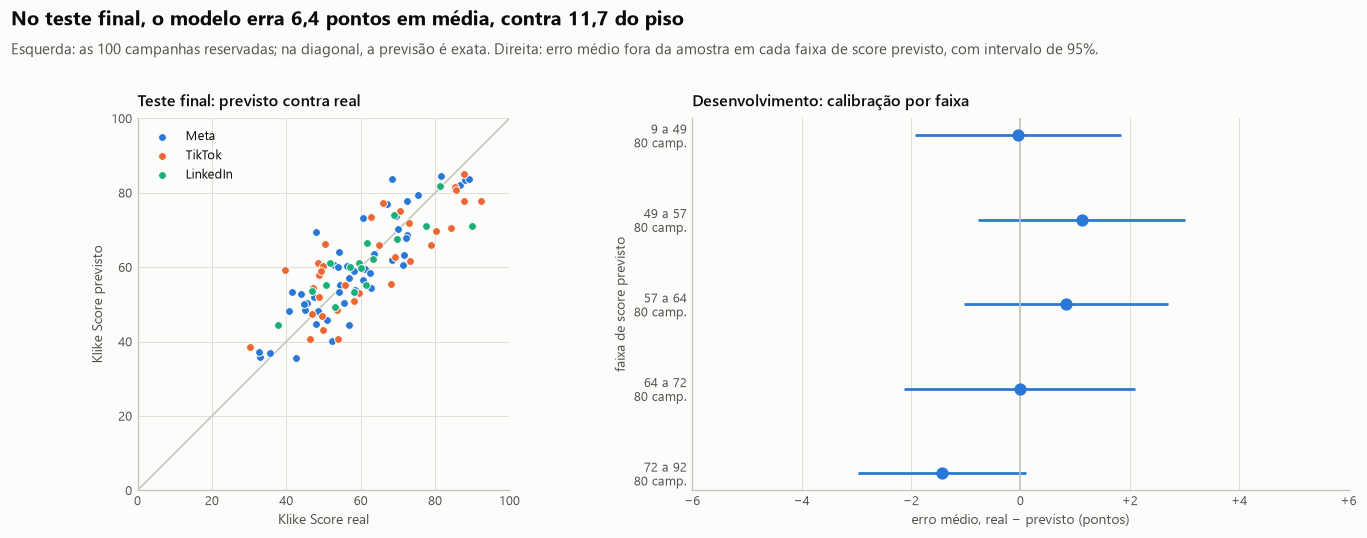

In [20]:
fig, (left, right) = plt.subplots(
    1, 2, figsize=(12.5, 5.0), gridspec_kw={"width_ratios": [1, 1.2]}
)
for platform in PLATFORMS:
    mask = (test["platform"] == platform).to_numpy()
    left.scatter(y_test[mask], test_predictions[mask], s=26, label=platform, linewidth=0.6,
                 color=viz.PLATFORM_COLORS[platform], edgecolor=viz.SURFACE, zorder=3)
left.plot([0, 100], [0, 100], color=viz.BASELINE, linewidth=1, zorder=1)
left.set(xlim=(0, 100), ylim=(0, 100), xlabel="Klike Score real", ylabel="Klike Score previsto")
left.set_aspect("equal")
left.legend(loc="upper left")
left.set_title("Teste final: previsto contra real")

rows = np.arange(len(calibration))[::-1]
right.errorbar(calibration["erro"], rows, xerr=calibration["margem"], fmt="o", markersize=7,
               color=viz.ACCENT, ecolor=viz.ACCENT, elinewidth=1.8, capsize=0)
right.axvline(0, color=viz.BASELINE, linewidth=1)
right.set_yticks(
    rows,
    [f"{label}\n{n} camp." for label, n in zip(calibration.index, calibration["campanhas"],
                                                strict=True)],
)
error_ticks = range(-6, 7, 2)
right.set_xticks(error_ticks, [fmt_signed(t) for t in error_ticks])
right.set_xlim(-6, 6)
right.set_ylabel("faixa de score previsto")
right.set_xlabel("erro médio, real − previsto (pontos)")
right.grid(axis="y", visible=False)
right.set_title("Desenvolvimento: calibração por faixa")
test_mae, baseline_mae = model_test.loc["mae", "estimativa"], baseline_test.loc["mae", "estimativa"]
viz.add_header(
    fig,
    f"No teste final, o modelo erra {fmt_number(test_mae, 1)} pontos em média, "
    f"contra {fmt_number(baseline_mae, 1)} do piso",
    "Esquerda: as 100 campanhas reservadas; na diagonal, a previsão é exata. Direita: erro médio "
    "fora da amostra em cada faixa de score previsto, com intervalo de 95%.",
)
viz.save(fig, "03_avaliacao")
plt.show()

## 9. O que o modelo aprendeu

Três perguntas diferentes, que não devem ser confundidas:

1. **O modelo prevê bem o score?** As seções 7 e 8 respondem.
2. **Quais variáveis pesam na previsão?** Esta seção responde, com os coeficientes e a importância por permutação.
3. **Mudar uma característica melhora a performance?** Nenhuma das duas medidas prova isso. Coeficientes e importância descrevem associações nos dados; a evidência sobre performance vem da Parte 1, e a confirmação, de testes A/B.

### 9.1 Efeitos em pontos de score

Coeficientes do modelo certificado, treinado nas 400 campanhas, convertidos em unidades legíveis. O desvio mostra quanto cada efeito variou ao reajustar o modelo nas 25 partições. A coluna da EDA traz o efeito estimado na Parte 1, com as 500 campanhas.

In [21]:
effects = linear_effects(certified.best_estimator_)
stability = pd.DataFrame(
    [
        linear_effects(
            tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC)
            .fit(X_development.iloc[train], y_development.iloc[train])
            .best_estimator_
        )
        for train, _ in splits
    ]
).std()

full = add_rate_metrics(cleaned).assign(musica_decimos=lambda d: d["music_voice_ratio"] * 10)
eda = estimate_effects(
    full, TARGET, log=False, terms={**CREATIVE_TERMS, "is_retargeting": "Retargeting"}
).set_index("atributo")["efeito"]
eda_music = fit_model(full, TARGET, log=False, extra="musica_decimos").params["musica_decimos"]
EDA_TERMS = {
    "has_hook": eda["Hook nos 3 primeiros segundos"],
    "has_face": eda["Rosto humano"],
    "subtitle_status_sim": eda["Legenda"],
    "has_cta": eda["Call-to-action"],
    "text_density_medium": eda["Texto médio (vs. baixo)"],
    "text_density_high": eda["Texto alto (vs. baixo)"],
    "music_voice_ratio": eda_music,
    "is_retargeting": eda["Retargeting"],
}
LEVER_TERMS = {
    "has_hook": "Hook nos 3 primeiros segundos",
    "has_face": "Rosto humano",
    "subtitle_status_sim": "Legenda (vs. sem legenda)",
    "subtitle_status_desconhecido": "Legenda sem marcação (vs. sem legenda)",
    "has_cta": "Call-to-action",
    "text_density_medium": "Texto médio (vs. baixo)",
    "text_density_high": "Texto alto (vs. baixo)",
    "music_voice_ratio": "Música/voz, a cada +0,1",
    "video_duration_s": "Duração, a cada +10 segundos",
}
CONTEXT_LABELS = {"category": "Categoria", "objective": "Objetivo",
                  "target_audience_age": "Faixa etária"}
CONTEXT_TERMS = {
    "is_retargeting": "Retargeting",
    **{
        f"{column}_{level}": f"{label} {level} (vs. {CATEGORY_ORDERS[column][0]})"
        for column, label in CONTEXT_LABELS.items()
        for level in CATEGORY_ORDERS[column][1:]
    },
}
display(
    pd.DataFrame(
        [
            {
                "grupo": group,
                "variável": label,
                "modelo (pontos)": fmt_signed(effects[term], 1),
                "desvio entre partições": fmt_number(stability[term], 1),
                "EDA (pontos)": fmt_signed(EDA_TERMS[term], 1) if term in EDA_TERMS else "",
            }
            for group, terms in [("alavanca do criativo", LEVER_TERMS), ("contexto", CONTEXT_TERMS)]
            for term, label in terms.items()
        ]
    ).set_index(["grupo", "variável"])
)

modelo (pontos)  \
grupo                variável                                                 
alavanca do criativo Hook nos 3 primeiros segundos                    +17,4   
                     Rosto humano                                     +11,3   
                     Legenda (vs. sem legenda)                         +8,2   
                     Legenda sem marcação (vs. sem legenda)            +2,9   
                     Call-to-action                                    +7,6   
                     Texto médio (vs. baixo)                           +7,4   
                     Texto alto (vs. baixo)                            −7,4   
                     Música/voz, a cada +0,1                           −0,4   
                     Duração, a cada +10 segundos                      −0,1   
contexto             Retargeting                                       +4,5   
                     Categoria SaaS (vs. E-commerce)                   +1,1   
                     Categoria Lead Gen (vs. E-commerce)               −0,4   
                     Categoria App Install (vs. E-commerce)            −2,5   
                     Categoria Branding (vs. E-commerce)               −2,8   
                     Objetivo traffic (vs. conversions)                −2,8   
                     Objetivo engagement (vs. conversions)             −3,0   
                     Objetivo awareness (vs. conversions)              −2,6   
                     Objetivo app_install (vs. conversions)            −3,1   
                     Faixa etária 25-34 (vs. 18-24)                    +2,3   
                     Faixa etária 35-44 (vs. 18-24)                    +1,6   
                     Faixa etária 45+ (vs. 18-24)                      +1,9   

                                                            desvio entre partições  \
grupo                variável                                                        
alavanca do criativo Hook nos 3 primeiros segundos                             0,5   
                     Rosto humano                                              0,4   
                     Legenda (vs. sem legenda)                                 0,5   
                     Legenda sem marcação (vs. sem legenda)                    1,1   
                     Call-to-action                                            0,5   
                     Texto médio (vs. baixo)                                   0,4   
                     Texto alto (vs. baixo)                                    0,6   
                     Música/voz, a cada +0,1                                   0,1   
                     Duração, a cada +10 segundos                              0,2   
contexto             Retargeting                                               0,5   
                     Categoria SaaS (vs. E-commerce)                           0,9   
                     Categoria Lead Gen (vs. E-commerce)                       1,0   
                     Categoria App Install (vs. E-commerce)                    0,9   
                     Categoria Branding (vs. E-commerce)                       1,3   
                     Objetivo traffic (vs. conversions)                        0,6   
                     Objetivo engagement (vs. conversions)                     1,1   
                     Objetivo awareness (vs. conversions)                      0,9   
                     Objetivo app_install (vs. conversions)                    1,2   
                     Faixa etária 25-34 (vs. 18-24)                            0,7   
                     Faixa etária 35-44 (vs. 18-24)                            0,6   
                     Faixa etária 45+ (vs. 18-24)                              0,7   

                                                            EDA (pontos)  
grupo                variável                                             
alavanca do criativo Hook nos 3 primeiros segundos                 +17,1  
                     Rosto humano     

**O modelo aprendeu o que a EDA mostrou.**

- **As alavancas do criativo dominam.** No modelo, hook (+17,4 pontos), rosto (+11,3), legenda (+8,2), CTA (+7,6) e texto médio (+7,4) somam pontos à previsão; texto alto tira 7,4. Os valores diferem dos da EDA em no máximo 0,6 ponto e variam pouco entre partições.
- **Música/voz e duração quase não pesam:** −0,4 ponto a cada +0,1 de música e praticamente zero para a duração.
- **O contexto pesa menos.** Retargeting soma 4,5 pontos; categoria, objetivo e faixa etária movem a previsão em até cerca de 3 pontos.
- **Legenda sem marcação fica entre os dois casos:** +2,9 pontos sobre "sem legenda", com o maior desvio entre as alavancas. É compatível com uma mistura de vídeos com e sem legenda, mas é o efeito menos estável do criativo.

Todos esses números são associações condicionais: comparam campanhas parecidas no resto. São a base para simular cenários no recommendations engine, mas não provam que mudar o atributo causa a mudança no score.

### 9.2 Formato dentro de cada plataforma

Com a interação F3, o efeito do formato muda conforme a plataforma. Como na Parte 1, cada formato é comparado com o mais usado na plataforma: vertical na Meta e no TikTok, horizontal no LinkedIn. A coluna da EDA repete a regressão da Parte 1, dentro de cada plataforma, com as 500 campanhas e intervalo de 95%.

In [22]:
def format_level(platform: str, fmt: str) -> float:
    """Pontos do formato contra o vertical, dentro da plataforma, no modelo certificado."""
    if fmt == "vertical":
        return 0.0
    return effects[f"format_{fmt}"] + effects.get(f"{platform} × {fmt}", 0.0)


def has_own_effect(platform: str, fmt: str) -> bool:
    """O modelo tem efeito aprendido para a combinação? O vertical e a Meta são referências."""
    return platform == "Meta" or fmt == "vertical" or f"{platform} × {fmt}" in effects.index


def count(frame: pd.DataFrame, platform: str, fmt: str) -> int:
    return int(((frame["platform"] == platform) & (frame["format"] == fmt)).sum())


format_rows = []
for platform in PLATFORMS:
    within = full[full["platform"] == platform]
    reference = within["format"].astype(str).value_counts().idxmax()
    eda_term = f"C(format, Treatment('{reference}'))"
    eda_fit = fit_model(
        within, TARGET, log=False, controls=CONTEXT_WITHIN_PLATFORM, extra=eda_term
    )
    for fmt in [f for f in CATEGORY_ORDERS["format"] if f != reference]:
        name = f"{eda_term}[T.{fmt}]"
        eda_text = "sem campanhas"
        if name in eda_fit.params:
            low, high = eda_fit.conf_int().loc[name]
            eda_text = (
                f"{fmt_signed(eda_fit.params[name], 1)} "
                f"({fmt_signed(low, 1)} a {fmt_signed(high, 1)})"
            )
        supported = has_own_effect(platform, fmt) and has_own_effect(platform, reference)
        model_effect = format_level(platform, fmt) - format_level(platform, reference)
        format_rows.append(
            {
                "plataforma": platform,
                "formato": fmt,
                "contra": reference,
                "campanhas na base": count(full, platform, fmt),
                "no desenvolvimento": count(development, platform, fmt),
                "modelo (pontos)": fmt_signed(model_effect, 1) if supported else "sem suporte",
                "EDA (intervalo de 95%)": eda_text,
            }
        )
display(pd.DataFrame(format_rows).set_index(["plataforma", "formato", "contra"]))
print(
    "Vídeos verticais no LinkedIn: "
    f"{count(full, 'LinkedIn', 'vertical')} na base, "
    f"{count(development, 'LinkedIn', 'vertical')} no desenvolvimento"
)
print(
    "Efeito principal do LinkedIn, que vale para o vídeo vertical: "
    f"{fmt_signed(effects['platform_LinkedIn'], 1)} pontos contra a Meta, com desvio de "
    f"{fmt_number(stability['platform_LinkedIn'], 1)} entre partições"
)

campanhas na base  no desenvolvimento  \
plataforma formato    contra                                              
Meta       quadrado   vertical                   68                  51   
           horizontal vertical                   67                  55   
TikTok     quadrado   vertical                   24                  19   
           horizontal vertical                    0                   0   
LinkedIn   vertical   horizontal                 11                   9   
           quadrado   horizontal                 28                  22   

                                 modelo (pontos) EDA (intervalo de 95%)  
plataforma formato    contra                                             
Meta       quadrado   vertical              +0,4     +0,6 (−1,9 a +3,1)  
           horizontal vertical              −4,9     −5,1 (−7,4 a −2,8)  
TikTok     quadrado   vertical              −3,0     −3,7 (−7,7 a +0,3)  
           horizontal vertical       sem suporte          sem campanhas  
LinkedIn   vertical   horizontal            −8,4    −9,3 (−18,8 a +0,1)  
           quadrado   horizontal            −6,4     −4,4 (−9,3 a +0,4)

Vídeos verticais no LinkedIn: 11 na base, 9 no desenvolvimento
Efeito principal do LinkedIn, que vale para o vídeo vertical: −10,3 pontos contra a Meta, com desvio de 2,9 entre partições


- **Na Meta,** o horizontal tem 4,9 pontos a menos que o vertical, e o quadrado empata, como na EDA.
- **No TikTok,** o quadrado tem 3,0 pontos a menos que o vertical; na EDA, 3,7, com intervalo que cruza o zero. Não há vídeo horizontal no TikTok, então o modelo não tem efeito próprio para essa combinação: uma previsão para ela seria extrapolação, e o engine deve tratá-la como sem suporte.
- **No LinkedIn,** o vertical tem 8,4 pontos a menos que o horizontal, e o quadrado, 6,4. A direção é a da EDA, mas lá os dois intervalos cruzam o zero, e o vertical tem só 11 campanhas na base, 9 delas no desenvolvimento. O modelo usa essas diferenças para prever; elas continuam sendo tendência, não conclusão.

**Duas cautelas de interpretação:**

- **Com a interação, o efeito principal de cada plataforma vale só para o vídeo vertical.** O do LinkedIn, de −10,3 pontos contra a Meta, depende de 9 campanhas verticais e varia bastante entre partições, com desvio de 2,9 pontos, contra cerca de 0,5 nas principais alavancas do criativo. Ele não deve ser lido sozinho: o que faz sentido comparar são as combinações de plataforma e formato.
- **A interação não é o efeito causal de trocar o formato.** Ela descreve diferenças de score entre combinações que existem na base, comparando campanhas parecidas no que foi medido. Formato e plataforma andam junto com outras escolhas: na Parte 1, os vídeos quadrados do TikTok tinham hook com menos frequência que os verticais, 33% contra 49%, e a diferença bruta de 12,7 pontos entre as medianas caiu para 3,7 com o ajuste. O que não foi medido, como a qualidade da produção, pode explicar parte do resto. Mudar o formato de um vídeo pronto não garante a diferença prevista.

### 9.3 Importância por permutação

Quanto o erro do modelo aumenta quando uma variável é embaralhada nas partições de validação do desenvolvimento, quebrando a relação dela com o score. As categorias de cada variável são embaralhadas juntas. Plataforma e formato andam juntos nos dados, então eles também são embaralhados em conjunto, para não criar combinações que não existem, como TikTok horizontal.

In [23]:
IMPORTANCE_GROUPS = {
    "Hook": ["has_hook"],
    "Rosto humano": ["has_face"],
    "Densidade de texto": ["text_density"],
    "Legenda": ["subtitle_status"],
    "Call-to-action": ["has_cta"],
    "Formato": ["format"],
    "Música/voz": ["music_voice_ratio"],
    "Duração": ["video_duration_s"],
    "Plataforma": ["platform"],
    "Retargeting": ["is_retargeting"],
    "Objetivo": ["objective"],
    "Categoria": ["category"],
    "Faixa etária": ["target_audience_age"],
}
JOINT = "Plataforma e formato, juntos"
IMPORTANCE_GROUPS[JOINT] = ["platform", "format"]
LEVERS = {"Hook", "Rosto humano", "Densidade de texto", "Legenda", "Call-to-action", "Formato",
          "Música/voz", "Duração"}
GROUP_KIND = {group: "alavanca do criativo" for group in LEVERS} | {JOINT: "contexto e criativo"}
per_partition = []
for number, (train, valid) in enumerate(splits[: modeling.N_SPLITS]):
    fitted = tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC).fit(
        X_development.iloc[train], y_development.iloc[train]
    )
    table = permutation_importance_by_group(
        fitted, X_development.iloc[valid], y_development.iloc[valid], IMPORTANCE_GROUPS,
        random_state=number,
    )
    per_partition.append(table.set_index("grupo")["aumento_mae"])
importance = pd.concat(per_partition, axis=1)
importance = pd.DataFrame(
    {"aumento": importance.mean(axis=1), "desvio": importance.std(axis=1)}
).sort_values("aumento", ascending=False)
display(
    importance.assign(
        tipo=[GROUP_KIND.get(group, "contexto") for group in importance.index],
        aumento=importance["aumento"].map(lambda v: fmt_number(round(v, 2) + 0.0, 2)),
        desvio=importance["desvio"].map(lambda v: fmt_number(v, 2)),
    )
    .rename(columns={"aumento": "aumento do MAE (pontos)", "desvio": "desvio entre partições"})
    .rename_axis("variável embaralhada")
)

,aumento do MAE (pontos),desvio entre partições,tipo
variável embaralhada,,,
Hook,"5,36","0,33",alavanca do criativo
Rosto humano,"2,60","0,36",alavanca do criativo
Densidade de texto,"2,30","0,44",alavanca do criativo
Legenda,"1,33","0,24",alavanca do criativo
Call-to-action,"1,07","0,37",alavanca do criativo
Plataforma,"0,93","0,31",contexto
"Plataforma e formato, juntos","0,78","0,20",contexto e criativo
Formato,"0,71","0,10",alavanca do criativo
Retargeting,"0,32","0,20",contexto


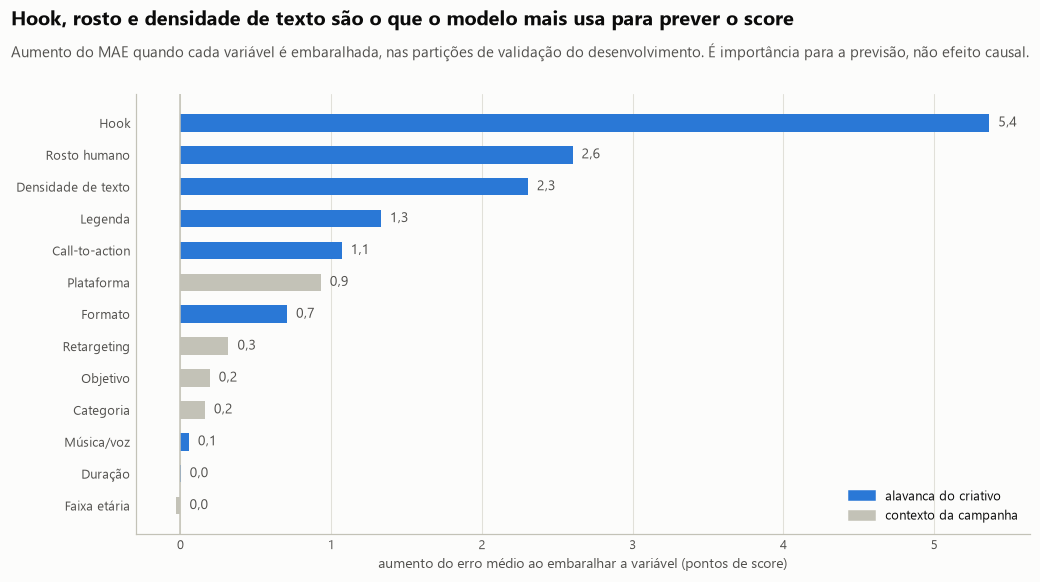

In [24]:
bars = importance.drop(index=JOINT).sort_values("aumento")
fig, ax = plt.subplots(figsize=(9.5, 5.4))
ax.barh(bars.index, bars["aumento"], height=0.55,
        color=[viz.ACCENT if g in LEVERS else viz.CONTEXT for g in bars.index])
for y, value in enumerate(bars["aumento"]):
    ax.text(max(value, 0) + 0.06, y, fmt_number(round(value, 1) + 0.0, 1), va="center",
            fontsize=9, color=viz.INK_SECONDARY)
ax.axvline(0, color=viz.BASELINE, linewidth=1)
ax.xaxis.set_major_formatter(viz.decimal_formatter(0))
ax.set_xlabel("aumento do erro médio ao embaralhar a variável (pontos de score)")
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[Patch(color=viz.ACCENT, label="alavanca do criativo"),
             Patch(color=viz.CONTEXT, label="contexto da campanha")],
    loc="lower right",
)
viz.add_header(
    fig,
    "Hook, rosto e densidade de texto são o que o modelo mais usa para prever o score",
    "Aumento do MAE quando cada variável é embaralhada, nas partições de validação do "
    "desenvolvimento. É importância para a previsão, não efeito causal.",
)
viz.save(fig, "03_importancia")
plt.show()

- **As alavancas do criativo dominam a previsão.** Embaralhar o hook aumenta o erro em 5,4 pontos; o rosto, em 2,6; a densidade de texto, em 2,3. Legenda e CTA vêm depois, perto de 1 ponto cada.
- **O contexto pesa pouco.** A plataforma é o maior, perto de 1 ponto; retargeting, objetivo e categoria ficam abaixo de meio ponto, e a faixa etária, em zero.
- **Música/voz e duração quase não ajudam a prever,** o que é coerente com os coeficientes perto de zero e com a Parte 1.
- **Embaralhar a plataforma sozinha superestima a importância dela.** Sozinha, ela aumenta o erro em 0,9 ponto; junto com o formato, em 0,8, embora o par carregue a informação das duas variáveis. Parte da importância isolada vem de combinações que quase não existem, como vídeo vertical no LinkedIn, onde o modelo extrapola. É a ressalva de correlação entre variáveis, medida na prática.

**Importância para a previsão não é alavanca de performance, nem efeito causal.** Ela mede quanto o modelo depende de uma variável para acertar o score, não o que acontece quando o criativo muda. O hook pesa muito no score, e a Parte 1 mostrou que ele também se associa a mais CTR e engajamento. Já legenda e CTA pesam no score sem efeito robusto em performance. Para o engine, o modelo diz quanto o score previsto muda, e a Parte 1 diz o que se sabe sobre a performance.

## 10. Modelo B: o score acompanha a performance?

O mesmo protocolo, agora com as sete taxas de performance, que só existem depois da veiculação: a especificação do modelo A, as mesmas 25 partições e, depois do modelo A, uma única consulta ao teste. Como o B é só comparativo, não há seleção própria de algoritmo ou de features para ele. Ele responde quanto do score acompanha a performance realizada e não serve para criativos novos.

In [25]:
X_post_development = prepare_post_flight_features(development)
X_post_test = prepare_post_flight_features(test)
b_folds = evaluate_on_splits(
    tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC, scenario="post"),
    X_post_development, y_development, splits,
)
display(
    pd.DataFrame(
        {
            "modelo A, pré-publicação": by_metric(lambda m: mean_and_spread(expected, m)),
            "modelo B, pós-publicação": by_metric(lambda m: mean_and_spread(b_folds, m)),
        }
    ).rename_axis("validação cruzada, média ± desvio")
)
display(
    pd.DataFrame({"modelo B sobre o modelo A": paired(b_folds, expected)})
    .T.rename_axis("comparação pareada")
)

B_GROUPS = {
    "atributos do criativo": ["has_hook", "has_face", "subtitle_status", "has_cta",
                              "text_density", "format", "video_duration_s", "music_voice_ratio"],
    "contexto da campanha": ["platform", "category", "objective", "target_audience_age",
                             "is_retargeting"],
    "taxas de performance": modeling.POST_FLIGHT_RATES,
}
b_importance = []
for number, (train, valid) in enumerate(splits[: modeling.N_SPLITS]):
    fitted = tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC, scenario="post").fit(
        X_post_development.iloc[train], y_development.iloc[train]
    )
    b_importance.append(
        permutation_importance_by_group(
            fitted, X_post_development.iloc[valid], y_development.iloc[valid], B_GROUPS,
            random_state=number,
        ).set_index("grupo")["aumento_mae"]
    )
display(
    pd.concat(b_importance, axis=1)
    .mean(axis=1)
    .map(lambda v: fmt_number(v, 2))
    .rename("aumento do MAE ao embaralhar o grupo (pontos)")
    .rename_axis("modelo B, grupo embaralhado")
    .to_frame()
)

,"modelo A, pré-publicação","modelo B, pós-publicação"
"validação cruzada, média ± desvio",,
MAE,"6,78 ± 0,48","5,42 ± 0,42"
RMSE,"8,50 ± 0,67","6,82 ± 0,51"
R²,"0,71 ± 0,04","0,81 ± 0,03"
Spearman,"0,83 ± 0,02","0,90 ± 0,02"


,redução do MAE (pontos),redução relativa,desvio da diferença,partições melhores (MAE),partições melhores (RMSE)
comparação pareada,,,,,
modelo B sobre o modelo A,"+1,36","+20,0%","0,47",100%,100%


,aumento do MAE ao embaralhar o grupo (pontos)
"modelo B, grupo embaralhado",
atributos do criativo,"7,49"
contexto da campanha,"1,11"
taxas de performance,"3,83"


**As taxas de performance acrescentam explicação.** Na validação cruzada, o modelo B erra 5,42 pontos, contra 6,78 do A: 1,36 ponto a menos, ou 20%, com melhora em todas as 25 partições. O R² passa de 0,71 para 0,81.

**Mesmo no modelo B, o criativo pesa mais que a performance.** Embaralhar os atributos do criativo aumenta o erro em 7,5 pontos, contra 3,8 das sete taxas juntas e 1,1 do contexto. Taxas e atributos andam juntos, como hook e CTR na Parte 1, então os grupos não se separam por completo. Ainda assim, a leitura é que o score acompanha a performance realizada só em parte e premia atributos do criativo por conta própria. Isso é coerente com a Parte 1, em que legenda e CTA somam pontos de score sem efeito robusto em performance.

**Essas conclusões valem para o score desta base simulada.** O peso relativo do criativo e da performance depende de como este score foi construído, e não deve ser transferido automaticamente para a metodologia real de produção da Klike.

A certificação do modelo B no teste vem depois da do modelo A e não muda nada nele:

In [26]:
certified_b =tuned(modeling.SELECTED_MODEL, modeling.SELECTED_SPEC, scenario="post").fit(
    X_post_development, y_development
)
b_test_predictions = certified_b.predict(X_post_test)
b_test = bootstrap_metrics(y_test, b_test_predictions)
display(
    pd.DataFrame(
        {
            "modelo A, no teste": by_metric(lambda m: with_interval(model_test, m)),
            "modelo B, no teste": by_metric(lambda m: with_interval(b_test, m)),
        }
    ).rename_axis("teste: estimativa (intervalo de 95%)")
)
b_gain = bootstrap_mae_gain(y_test, b_test_predictions, test_predictions)
print(
    f"Redução do MAE do modelo B sobre o A no teste: {fmt_number(b_gain['estimativa'], 2)} "
    f"pontos, com intervalo de 95% de {fmt_number(b_gain['ic_inferior'], 2)} a "
    f"{fmt_number(b_gain['ic_superior'], 2)}"
)

,"modelo A, no teste","modelo B, no teste"
teste: estimativa (intervalo de 95%),,
MAE,"6,43 (5,55 a 7,33)","5,29 (4,56 a 6,06)"
RMSE,"7,92 (6,86 a 8,96)","6,56 (5,74 a 7,32)"
R²,"0,70 (0,57 a 0,78)","0,79 (0,71 a 0,85)"
Spearman,"0,83 (0,74 a 0,88)","0,89 (0,83 a 0,92)"


Redução do MAE do modelo B sobre o A no teste: 1,13 pontos, com intervalo de 95% de 0,26 a 2,00


No teste, o modelo B erra 5,29 pontos, contra 6,43 do A: 1,13 ponto a menos, com intervalo de 0,26 a 2,00, em linha com o ganho da validação cruzada. O modelo B não entra no recommendations engine nem substitui o A. As métricas que valem para criativos novos são as do modelo A, na seção 7.

## 11. O que isso significa para a Klike

- **Dá para pontuar um criativo antes de gastar.** Só com o que se sabe antes da veiculação, o modelo erra 6 a 7 pontos em média, numa escala de 0 a 100: cerca de 45% menos que usar a média histórica.
- **O score previsto serve para separar criativos, não para cravar números.** Quando o modelo prevê 10 pontos ou mais de diferença entre dois criativos da mesma plataforma, o apontado como melhor teve de fato o maior score em 93% dos pares do desenvolvimento; abaixo de 5 pontos previstos, em 58%, pouco acima de um chute. A diferença prevista indica a confiança na comparação, numa leitura exploratória que ainda não define um limiar. Nos extremos, a previsão é conservadora: um criativo excepcional tende a receber nota abaixo da real, e um muito fraco, acima.
- **É a base do recommendations engine, na Parte 3.** Os efeitos em pontos permitem estimar quanto o score previsto muda com um ajuste no criativo, como incluir hook. É uma estimativa baseada em associação, não uma garantia. Cada sugestão deve trazer o nível de evidência da Parte 1 sobre performance, o engine deve sinalizar mais incerteza no LinkedIn e recusar combinações sem suporte, como TikTok horizontal.
- **O score não é a performance.** Nesta base simulada, a performance realizada explica só parte do score, e o score premia legenda, CTA e texto médio sem efeito robusto em performance. Vale validar esses pesos com o time da Klike, sem supor que o score real de produção se comporte igual.
- **Onde mais dados ajudariam:** campanhas no LinkedIn, sobretudo verticais, e um identificador de criativo, para garantir que versões do mesmo anúncio não fiquem dos dois lados da divisão.

## 12. Modelo final para uso

Depois da certificação, a especificação congelada é reajustada nas 500 campanhas, com a penalização da certificação (alpha 1) e sem nova busca de hiperparâmetros. O reajuste também treina com as 100 campanhas do teste. Por isso, não ganha métrica própria: não sobra nenhuma campanha para avaliá-lo de forma independente. As métricas oficiais continuam sendo as da seção 7.

O treino, a persistência e a previsão ficam em `src/klike/predictor.py`, e `python -m klike.train` gera o arquivo do modelo, que não vai para o repositório. Aqui, o mesmo código treina o modelo final para mostrar o que muda com o reajuste e como ele é usado.

### 12.1 O que muda com o reajuste

In [27]:
final = train_final_model()
training = final.metadata["treino"]
print(
    f"Modelo final: {training['campanhas']} campanhas | alpha "
    f"{fmt_compact(final.metadata['especificacao']['alpha'])} | interações: "
    f"{', '.join(training['interacoes_plataforma_formato'])}"
)
FORMAT_TERMS = {
    "format_quadrado": "Formato quadrado (vs. vertical, na Meta)",
    "format_horizontal": "Formato horizontal (vs. vertical, na Meta)",
}
INTERACTION_TERMS = {
    term: f"Interação {term}" for term in training["interacoes_plataforma_formato"]
}
shown = {**LEVER_TERMS, **FORMAT_TERMS, **INTERACTION_TERMS, **CONTEXT_TERMS}
refit = pd.DataFrame(
    {"certificado, 400 campanhas": effects, "final, 500 campanhas": linear_effects(final.pipeline)}
).loc[list(shown)]
refit["mudança"] = refit["final, 500 campanhas"] - refit["certificado, 400 campanhas"]
display(refit.rename(index=shown).map(lambda v: fmt_signed(v, 1)).rename_axis("efeito em pontos"))

Modelo final: 500 campanhas | alpha 1 | interações: TikTok × quadrado, LinkedIn × quadrado, LinkedIn × horizontal


,"certificado, 400 campanhas","final, 500 campanhas",mudança
efeito em pontos,,,
Hook nos 3 primeiros segundos,"+17,4","+17,0","−0,4"
Rosto humano,"+11,3","+11,8","+0,5"
Legenda (vs. sem legenda),"+8,2","+8,3","+0,1"
Legenda sem marcação (vs. sem legenda),"+2,9","+2,9",0
Call-to-action,"+7,6","+8,1","+0,6"
Texto médio (vs. baixo),"+7,4","+6,8","−0,6"
Texto alto (vs. baixo),"−7,4","−7,2","+0,3"
"Música/voz, a cada +0,1","−0,4","−0,5","−0,1"
"Duração, a cada +10 segundos","−0,1","−0,2","−0,1"


**O reajuste muda pouco o modelo.** Nenhum efeito muda de sinal. As alavancas do criativo mudam no máximo 0,6 ponto e, em geral, ficam mais perto dos efeitos da EDA, estimados nas mesmas 500 campanhas: o hook passa de +17,4 para +17,0 (EDA: +17,1), e o CTA, de +7,6 para +8,1 (EDA: +8,2). As interações mudam menos de 1 ponto, e os termos de contexto, até 1,2.

### 12.2 Como usar

Uma única chamada valida a campanha, prepara as features, aplica o pipeline e devolve o score previsto, limitado à escala de 0 a 100. Quem usa o modelo não precisa conhecer o pré-processamento.

In [28]:
new_campaign = {
    "platform": "TikTok",
    "category": "E-commerce",
    "objective": "conversions",
    "target_audience_age": "18-24",
    "is_retargeting": False,
    "video_duration_s": 15,
    "format": "vertical",
    "has_subtitle": True,
    "has_cta": True,
    "has_hook": True,
    "has_face": True,
    "text_density": "medium",
    "music_voice_ratio": 0.4,
}
examples = {
    "campanha nova": new_campaign,
    "a mesma, sem hook": {**new_campaign, "has_hook": False},
    "a mesma, sem duração nem legenda informadas": {
        **new_campaign,
        "video_duration_s": None,
        "has_subtitle": None,
    },
}
display(
    final.predict(list(examples.values()))
    .set_axis(list(examples))
    .map(lambda v: fmt_number(v, 1))
    .rename("score previsto")
    .to_frame()
)
history = final.predict(cleaned)
print(
    f"Nas 500 campanhas do histórico, as previsões vão de {fmt_number(history.min(), 1)} "
    f"a {fmt_number(history.max(), 1)}: o limite de 0 a 100 é só uma proteção."
)
try:
    final.predict({**new_campaign, "platform": "YouTube", "music_ratio": 0.4})
except ValueError as error:
    print(error)

,score previsto
campanha nova,"88,3"
"a mesma, sem hook","71,3"
"a mesma, sem duração nem legenda informadas","82,9"


Nas 500 campanhas do histórico, as previsões vão de 15,3 a 90,2: o limite de 0 a 100 é só uma proteção.
Entrada inválida: campos desconhecidos ['music_ratio'] (o modelo usa platform, category, objective, target_audience_age, is_retargeting, video_duration_s, format, has_subtitle, has_cta, has_hook, has_face, text_density, music_voice_ratio); platform: valor desconhecido ['YouTube'] (aceitos: Meta, TikTok, LinkedIn).


- **Campos opcionais podem faltar.** Sem duração, o pipeline usa a mediana do treino; sem a marcação de legenda, a campanha entra como "desconhecida", como no histórico.
- **Entradas erradas param a previsão com uma mensagem que lista todos os problemas,** inclusive um campo com o nome digitado errado. Sem essa checagem, um campo opcional com nome errado viraria um valor ausente em silêncio.
- **A diferença entre as duas primeiras linhas é o efeito do hook no modelo,** cerca de 17 pontos. É uma diferença prevista, baseada em associação, e não a garantia de que acrescentar um hook a este vídeo traga esses pontos (seção 9).

### 12.3 Suporte histórico para a Parte 3

O modelo devolve um score para qualquer combinação válida, mesmo as que quase não aparecem na base. O suporte histórico guarda os atributos de pré-publicação das 500 campanhas, sem score nem métricas, e conta campanhas parecidas em qualquer recorte, sem exigir que as 13 features coincidam.

In [29]:
display(
    final.support.table("platform", "format")
    .unstack()
    .rename_axis(index="plataforma", columns="formato")
)
levels = [
    ["platform", "format", "category", "objective"],
    ["platform", "format", "category"],
    ["platform", "format"],
    ["platform"],
    [],
]
linkedin_vertical = {
    **new_campaign,
    "platform": "LinkedIn",
    "format": "vertical",
    "category": "SaaS",
}
display(
    final.support.counts_for(linkedin_vertical, levels)
    .rename_axis("campanhas iguais em")
    .to_frame()
)

formato,vertical,quadrado,horizontal
plataforma,,,
Meta,106,68,67
TikTok,152,24,0
LinkedIn,11,28,44


,campanhas
campanhas iguais em,
platform + format + category + objective,1
platform + format + category,2
platform + format,11
platform,83
todas,500


- **TikTok horizontal não tem nenhuma campanha.** O modelo ainda devolve um score, somando os efeitos gerais, mas é uma extrapolação que o engine precisa sinalizar.
- **O recorte pode ser alargado aos poucos.** Para uma campanha vertical de SaaS no LinkedIn, só 1 campanha da base coincide em plataforma, formato, categoria e objetivo. Sem o objetivo, são 2; só com plataforma e formato, 11; na plataforma, 83. Na Parte 3, o engine decide em que nível se apoiar, e com quanta cautela.
- **O suporte conta campanhas; ele não mede se um efeito vale naquele grupo.** Essa avaliação, com encolhimento em direção ao efeito geral, fica para o engine.

**Limitações do modelo final:**

- **Não tem métrica própria.** As oficiais são as da certificação; a próxima avaliação independente exigiria campanhas novas.
- **Herda as limitações da certificação:** previsões conservadoras nos extremos, mais erro no LinkedIn e efeitos que descrevem associação, não causa.
- **O arquivo salvo depende da versão do scikit-learn.** Se ela mudar, `python -m klike.train` recria o arquivo, e o carregamento avisa da diferença.